In [1]:
import os
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

def loadData(folder, label, image_size=(32, 32)):
    data = []
    for filename in os.listdir(folder):
        if filename.lower().endswith(('.jpg', '.jpeg', '.png')):
            path = os.path.join(folder, filename)
            try:
                img = Image.open(path).convert('RGB')
                img = img.resize(image_size)
                img_array = np.array(img).flatten() / 255.0
                data.append((img_array, label))
            except Exception as e:
                print(f"Eroare la {filename}: {e}")
    return data



normalData = loadData('photos', label=0)
sepiaData = loadData('photos_sepia', label=1)

allData = normalData + sepiaData
np.random.shuffle(allData)

inputs = [x[0] for x in allData]
outputs = [x[1] for x in allData]



In [2]:
def splitData(inputs_data, outputs_data):
    np.random.seed(5)
    indexes = [i for i in range(len(inputs_data))]
    trainSample = np.random.choice(indexes, int(0.8 * len(inputs_data)), replace = False)
    testSample = [i for i in indexes  if not i in trainSample]

    trainInputs = [inputs_data[i] for i in trainSample]
    trainOutputs = [outputs_data[i] for i in trainSample]
    testInputs = [inputs_data[i] for i in testSample]
    testOutputs = [outputs_data[i] for i in testSample]

    return trainInputs, trainOutputs, testInputs, testOutputs

trainInputs, trainOutputs, testInputs, testOutputs = splitData(inputs, outputs)
print(f"Train set: {len(trainInputs)} imagini")
print(f"Test set: {len(testOutputs)} imagini")


Train set: 139 imagini
Test set: 35 imagini


Epoch 1/200, loss: 0.6941
Epoch 100/200, loss: 0.6524
Epoch 200/200, loss: 0.2099
Accuracy: 0.9142857142857143
Precision: [0.85 1.  ]
Recall:    [1.         0.83333333]


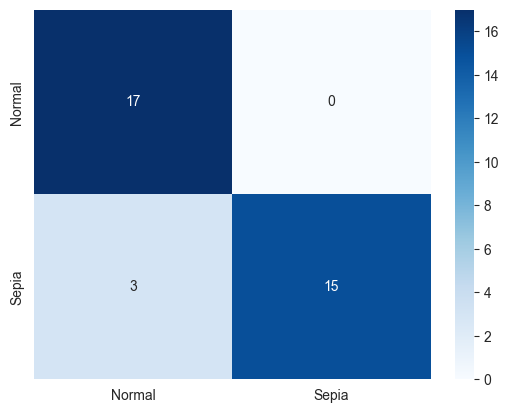

In [21]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
from CNN import CNN

clf = CNN(
    image_size=(32,32),
    in_channels=3,
    num_classes=2,
    learning_rate=0.01,
    epochs=200,
)

clf.fit(trainInputs, trainOutputs)
preds = clf.predict(testInputs)


print("Accuracy:", accuracy_score(testOutputs, preds))
print("Precision:", precision_score(testOutputs, preds, average=None, zero_division=0))
print("Recall:   ", recall_score(testOutputs, preds, average=None, zero_division=0))

cm = confusion_matrix(testOutputs, preds)
sns.heatmap(cm, annot=True, fmt="d",
            xticklabels=["Normal","Sepia"],
            yticklabels=["Normal","Sepia"],
            cmap="Blues")
plt.show()





Epoch 1/100, loss: 0.6972
Epoch 100/100, loss: 0.6143
Accuracy: 0.6857142857142857
Precision normal: 0.7142857142857143
Precision sepia: 0.6666666666666666
Recall normal: 0.5882352941176471
Recall sepia: 0.7777777777777778


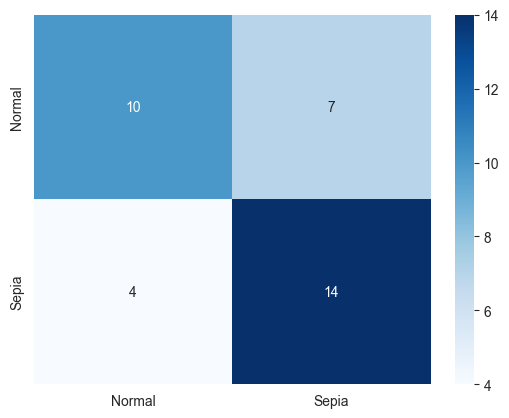

In [24]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
from CNN import CNN

clf = CNN(
    image_size=(32,32),
    in_channels=3,
    num_classes=2,
    learning_rate=0.01,
    epochs=100,
)

clf.fit(trainInputs, trainOutputs)
preds = clf.predict(testInputs)


acc = accuracy_score(testOutputs, preds)
precision = precision_score(testOutputs, preds, average=None, zero_division=0)
recall = recall_score(testOutputs, preds, average=None, zero_division=0)

print("Accuracy:", acc)
print("Precision normal:", precision[0])
print("Precision sepia:", precision[1])
print("Recall normal:", recall[0])
print("Recall sepia:", recall[1])


cm = confusion_matrix(testOutputs, preds)
sns.heatmap(cm, annot=True, fmt="d",
            xticklabels=["Normal","Sepia"],
            yticklabels=["Normal","Sepia"],
            cmap="Blues")
plt.show()



